# Feature Stability Under Three Alternating Tasks

**Question:** A learner with features for two teachers alternates among three for a long time. How close do SGD and Autostep get to a network that keeps fixed true features for every teacher and re-adapts the rest?

Three fixed teachers, as in 05: 21 independent ±1 inputs → 10 LTUs → 10 linear outputs, ±1 weights, Gaussian target noise of standard deviation 1. Training cycles teacher 1 → 2 → 3 → 1 → … in that fixed order, switching every 10,000 examples, for 2M examples. No task ID is supplied. The learner has **21 inputs → 20 LTUs → 10 linear outputs**, enough features for two teachers.

Three methods, 30 shared seeds:
- SGD with step size $2^{-6}$ (the best whole-run rate in 05) and fan-in initialization.
- Network Autostep with standardized hidden units, exactly as in 10.
- **Baseline: 4 frozen true features per teacher.** Autostep as above, but 12 of its 20 hidden units are copies of 4 true LTUs from each teacher, and their input weights never change. The other 8 hidden units and the readout learn.

The plot shows RMSE averaged over 1k-step windows for the first and last 80k steps: the mean over seeds, with a 95% confidence band.

In [1]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 3
N_HIDDEN = 2 * WIDTH  # capacity for two of the three teachers

# Autostep: standardized hidden units and small hidden initialization.
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3
VAR_FLOOR = .01  # floor on a hidden unit's variance: protects units firing on about 1% to 99% of inputs

# Training
PERIOD = 10_000  # examples per block; the teacher changes every block
STEPS = 2_000_000
BLOCKS = STEPS // PERIOD
WINDOW = 1000
PLOT_STEPS = 80_000  # steps shown at the start and at the end of the plot
FLIPS = 10  # task flips shown in the hidden-unit plot
GIVEN = 4  # baseline: true teacher LTUs per teacher given as frozen hidden units
SGD_RATE = 2. ** -6
N_SEEDS = 30

## Task

In [3]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > 0).astype(jnp.float32)


def teachers_for(seed):
    teacher_key = jax.random.split(jax.random.PRNGKey(seed), 3)[0]
    return jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple
    covs: tuple


def init_learner(key, widths, method):
    weights = []
    fan_in = N_INPUTS
    for width, subkey in zip(widths, jax.random.split(key, len(widths))):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound)
        weights.append(w.at[:, -1].set(0.))
        fan_in = width
    weights.append(jnp.zeros((N_OUTPUTS, fan_in + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(w.shape[0], .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w) for w in weights[:-1]))


def forward(weights, x, learner, method):
    sources, means, slopes, covs = [], [], [], []
    for w, mean, slope, cov in zip(weights[:-1], learner.means, learner.slopes, learner.covs):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        x = ltu(z)
        if method == 'Autostep':
            # Standardization (09): the centering of network_autostep, then division by the running standard deviation.
            # The backward pass accounts for how the mean and the standard deviation change with the input weights.
            mean = mean + EMA_RATE * (jax.lax.stop_gradient(x) - mean)
            sigmoid = jax.nn.sigmoid(z)
            derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))[:, None] * jax.lax.stop_gradient(source)
            slope = slope + EMA_RATE * (derivative - slope)
            correction = jnp.sum(slope * w, axis=1)
            centered = jax.lax.stop_gradient(x - mean)
            # cov tracks Cov(h, sigma'(z) x), half the derivative of the unit's variance with respect to its input weights.
            cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
            var = mean * (1 - mean)
            change = jnp.sum(cov * w, axis=1)
            x = x - mean + (jax.lax.stop_gradient(correction) - correction)
            x = x - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / jnp.maximum(var, VAR_FLOOR), 0.)
            x = x / jax.lax.stop_gradient(jnp.sqrt(jnp.maximum(var, VAR_FLOOR)))
        means.append(mean)
        slopes.append(slope)
        covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def update(learner, x, y, method, rate, frozen=0):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, means, slopes, covs)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    # The first `frozen` hidden units keep their input weights.
    updates = (updates[0].at[:frozen].set(0.), updates[1])
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, means, slopes, covs), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, method, given, tasks):
    learner_key, rng = jax.random.split(jax.random.PRNGKey(seed), 3)[1:]
    teachers = teachers_for(seed)
    learner = init_learner(learner_key, (N_HIDDEN,), method)
    # The first `given` LTUs of every teacher become the first hidden units (teacher LTUs have no bias).
    true = jnp.pad(teachers[0][:, :given].reshape(-1, N_INPUTS), ((0, 0), (0, 1)))
    learner = learner._replace(weights=(learner.weights[0].at[:len(true)].set(true), learner.weights[1]))

    def block(carry, block_id):
        # Cycle through the first `tasks` teachers: 1, 2, 3, 1, ...
        teacher = jax.tree.map(lambda w: w[block_id % tasks], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            learner, mse = update(learner, x, y, method, SGD_RATE, frozen=N_TASKS * given)
            return (learner, rng), mse

        def record(carry, _):
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, (mse.mean(), carry[0].weights[0])
        return jax.lax.scan(record, carry, length=PERIOD // WINDOW)

    _, (mse, hidden) = jax.lax.scan(block, (learner, rng), jnp.arange(BLOCKS))
    # Window means of the MSE, and the hidden units' input weights at the end of each window of the last FLIPS + 1 blocks.
    return mse.reshape(-1), hidden.reshape(-1, N_HIDDEN, N_INPUTS + 1)[-(FLIPS + 1) * PERIOD // WINDOW:]


@partial(jax.jit, static_argnames=('method', 'given', 'tasks'))
def train_many(seeds, method, given, tasks):
    return jax.vmap(partial(train, method=method, given=given, tasks=tasks))(seeds)


def run(method, given=0, tasks=N_TASKS):
    started = perf_counter()
    mse, hidden = jax.tree.map(np.asarray, train_many(jnp.arange(N_SEEDS), method, given, tasks))
    assert np.isfinite(mse).all()
    print(f'{method}{f" with {given} frozen true features per teacher" if given else ""}, {tasks} tasks: '
          f'{perf_counter() - started:.1f}s including compilation')
    return mse, hidden

In [6]:
started = perf_counter()
runs = {rf'SGD $2^{{-6}}$': run('SGD'), 'Autostep': run('Autostep'),
        f'Baseline: {GIVEN} frozen true features per teacher': run('Autostep', given=GIVEN)}
results = {label: mse for label, (mse, _) in runs.items()}
hidden = {label: weights for label, (_, weights) in runs.items()}
seconds = perf_counter() - started
np.savez_compressed(RESULTS / 'feature_stability.npz', sgd=results[rf'SGD $2^{{-6}}$'], autostep=results['Autostep'],
                    frozen=results[f'Baseline: {GIVEN} frozen true features per teacher'], seconds=seconds)
print(f'Complete comparison: {seconds:.1f}s including compilation.')

SGD, 3 tasks: 22.3s including compilation


Autostep, 3 tasks: 33.8s including compilation


Autostep with 4 frozen true features per teacher, 3 tasks: 34.6s including compilation
Complete comparison: 90.7s including compilation.


## Plot

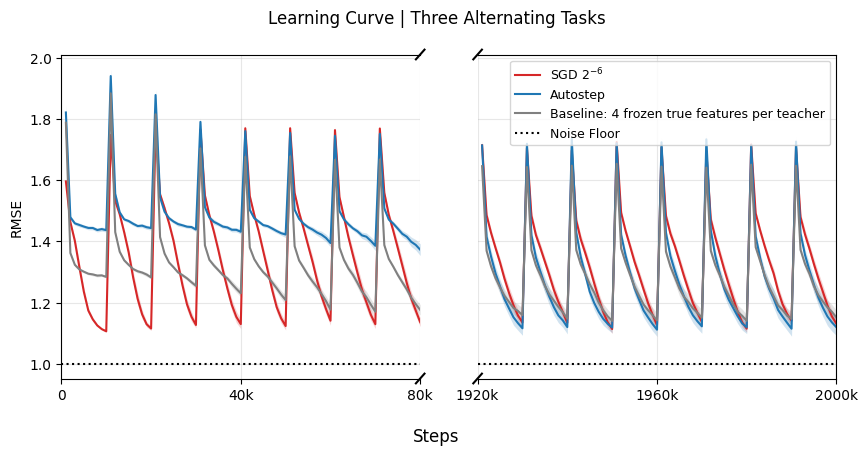

SGD $2^{-6}$: RMSE over the second half 1.342
Autostep: RMSE over the second half 1.298
Baseline: 4 frozen true features per teacher: RMSE over the second half 1.290


In [7]:
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True, gridspec_kw={'wspace': .16})
for ax, (left, right) in zip(axes, ((0, PLOT_STEPS), (STEPS - PLOT_STEPS, STEPS))):
    visible = (x > left) & (x <= right)
    for (label, mse), color in zip(results.items(), ('C3', 'C0', 'gray')):
        rmse = np.sqrt(mse[:, visible])
        mean, ci = rmse.mean(0), 1.96 * rmse.std(0) / np.sqrt(N_SEEDS)
        ax.plot(x[visible], mean, color=color, label=label)
        ax.fill_between(x[visible], mean - ci, mean + ci, color=color, alpha=.2, lw=0)
    ax.axhline(1., color='black', ls=':', label='Noise Floor')
    ax.set_xlim(left, right)
    ticks = np.linspace(left, right, 3)
    ax.set_xticks(ticks, ['0' if t == 0 else f'{t / 1000:g}k' for t in ticks])
    ax.grid(True, alpha=.3)
axes[0].spines['right'].set_visible(False)
axes[1].spines['left'].set_visible(False)
axes[1].tick_params(axis='y', left=False)
# Diagonal bars mark the omitted middle interval; the two time spans are equal.
for ax, side in ((axes[0], 1), (axes[1], 0)):
    for height in (0, 1):
        ax.plot((side-.012, side+.012), (height-.015, height+.015), transform=ax.transAxes, color='black', clip_on=False, lw=1.5)
axes[0].set_ylabel('RMSE')
axes[1].legend(fontsize=9)
fig.suptitle('Learning Curve | Three Alternating Tasks')
fig.supxlabel('Steps')
fig.subplots_adjust(bottom=.16, top=.88)
plt.show()
for label, mse in results.items():
    print(f'{label}: RMSE over the second half {np.sqrt(mse[:, mse.shape[1] // 2:].mean(1)).mean():.3f}')

**Result (90.9s on GPU):** keeping 4 fixed true features per teacher gives almost no gain over Autostep once Autostep has learned. Over the second half, the baseline's RMSE is 1.290, Autostep's 1.298 and SGD's 1.342. The baseline is ahead only early, because it starts with true features.

## Hidden Units Over the Last 10 Task Flips

One row per hidden unit of seed 0, from snapshots of its input weights every 1k steps over the last 11 blocks (the block before the last 10 flips, then those 10 flips). The strip on top shows the active task. In the baseline, the 12 frozen true features are the rows above the black line.

**Which task a unit is most useful for.** Take the unit's 0/1 firing $h$ on 1000 fixed random inputs. For each teacher, compute the fraction of its noise-free target variance, summed over its 10 outputs, that $h$ alone explains with the best output weights and bias: $\sum_k \mathrm{Cov}(h, y_k)^2 / \big(\mathrm{Var}(h) \sum_k \mathrm{Var}(y_k)\big)$. Divide by the average of that fraction for that teacher's own true LTUs (about 0.1), so 1 means as useful as a true LTU. The unit is most useful for the teacher with the largest ratio: the color shows that teacher, and its strength shows the ratio, capped at 1. White means useful for no task, including a unit that stops firing.

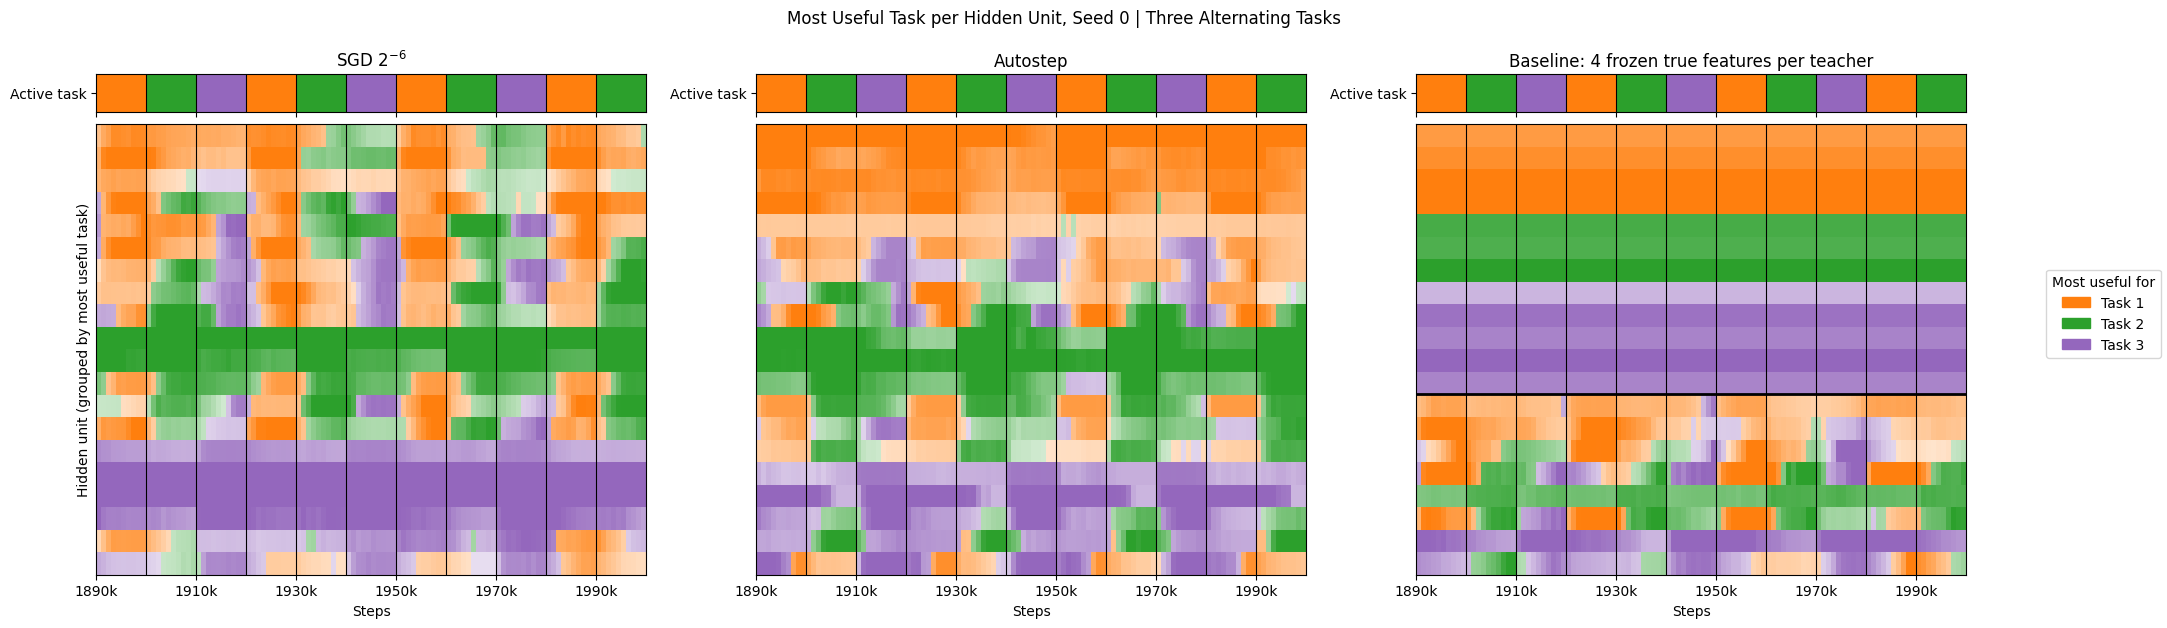

In [8]:
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

TASK_COLORS = np.array([to_rgb(c) for c in ('tab:orange', 'tab:green', 'tab:purple')])
probe = np.random.default_rng(0).choice([-1., 1.], (1000, N_INPUTS)).astype(np.float32)


def explained(firing, targets):
    # firing: (..., unit, probe); targets: (task, probe, output). Returns (..., unit, task): the fraction of each task's
    # target variance, summed over outputs, that the unit's firing alone explains with the best output weights and bias.
    f = firing - firing.mean(-1, keepdims=True)
    t = targets - targets.mean(-2, keepdims=True)
    cov = np.einsum('...up,tpk->...utk', f, t) / f.shape[-1]
    return (cov ** 2).sum(-1) / (f.var(-1)[..., None] * t.var(-2).sum(-1) + 1e-12)


seed = 0
teachers = teachers_for(seed)
targets = np.asarray(jax.vmap(lambda w, v: jax.vmap(lambda x: target((w, v), x))(probe))(*teachers))
true_firing = np.asarray(teachers[0] @ probe.T > 0, dtype=np.float32)  # (task, LTU, probe)
reference = np.diagonal(explained(true_firing, targets).mean(-2))  # average for a true LTU of the same task

def plot_units(columns, tasks, problem):
    # columns: (label, hidden-unit weights, number of leading frozen units) for each method.
    start = STEPS - (FLIPS + 1) * PERIOD
    fig, axes = plt.subplots(2, len(columns), figsize=(7 * len(columns) + 1, 6.5), sharex=True,
                             gridspec_kw={'height_ratios': (1, 12), 'hspace': .05})
    for column, (label, weights, frozen) in zip(axes.T, columns):
        firing = (weights[seed] @ np.append(probe, np.ones((len(probe), 1)), axis=1).T > 0).astype(np.float32)
        usefulness = explained(firing, targets[:tasks]) / reference[:tasks]  # (snapshot, unit, task)
        best, strength = usefulness.argmax(-1), np.clip(usefulness.max(-1), 0, 1)
        image = 1 - strength[..., None] * (1 - TASK_COLORS[best])
        # Frozen units first, then rows grouped by the task each unit is most often most useful for.
        counts = np.stack([(best == t).sum(0) for t in range(tasks)], -1)
        order = np.lexsort((-counts.max(-1), counts.argmax(-1), (np.arange(N_HIDDEN) >= frozen).astype(int)))
        column[1].imshow(image[:, order].transpose(1, 0, 2), aspect='auto', interpolation='nearest',
                         extent=(start, STEPS, N_HIDDEN, 0))
        if frozen:
            column[1].axhline(frozen, color='black', lw=2)
        column[0].imshow(TASK_COLORS[np.arange(BLOCKS - FLIPS - 1, BLOCKS) % tasks][None], aspect='auto',
                         extent=(start, STEPS, 0, 1))
        for ax in column:
            for flip in range(start + PERIOD, STEPS, PERIOD):
                ax.axvline(flip, color='black', lw=.8)
        column[0].set_title(label)
        column[0].set_yticks([.5], ['Active task'])
        column[1].set_yticks([])
        column[1].set_xticks(range(start, STEPS + 1, 2 * PERIOD), [f'{t / 1000:g}k' for t in range(start, STEPS + 1, 2 * PERIOD)])
        column[1].set_xlabel('Steps')
    axes[1, 0].set_ylabel('Hidden unit (grouped by most useful task)')
    fig.legend(handles=[Patch(color=c, label=f'Task {t + 1}') for t, c in enumerate(TASK_COLORS[:tasks])], loc='center right',
               title='Most useful for')
    fig.suptitle(f'Most Useful Task per Hidden Unit, Seed {seed} | {problem}')
    fig.subplots_adjust(left=.06, right=.91)
    plt.show()


plot_units([(label, weights, N_TASKS * GIVEN if label.startswith('Baseline') else 0) for label, weights in hidden.items()],
           N_TASKS, 'Three Alternating Tasks')

**Two tasks.** The same plot when training cycles only teachers 1 and 2, which the learner has the capacity for. Same seeds and teachers; SGD and Autostep only. Usefulness is compared over these two tasks only.

SGD, 2 tasks: 22.6s including compilation


Autostep, 2 tasks: 34.3s including compilation


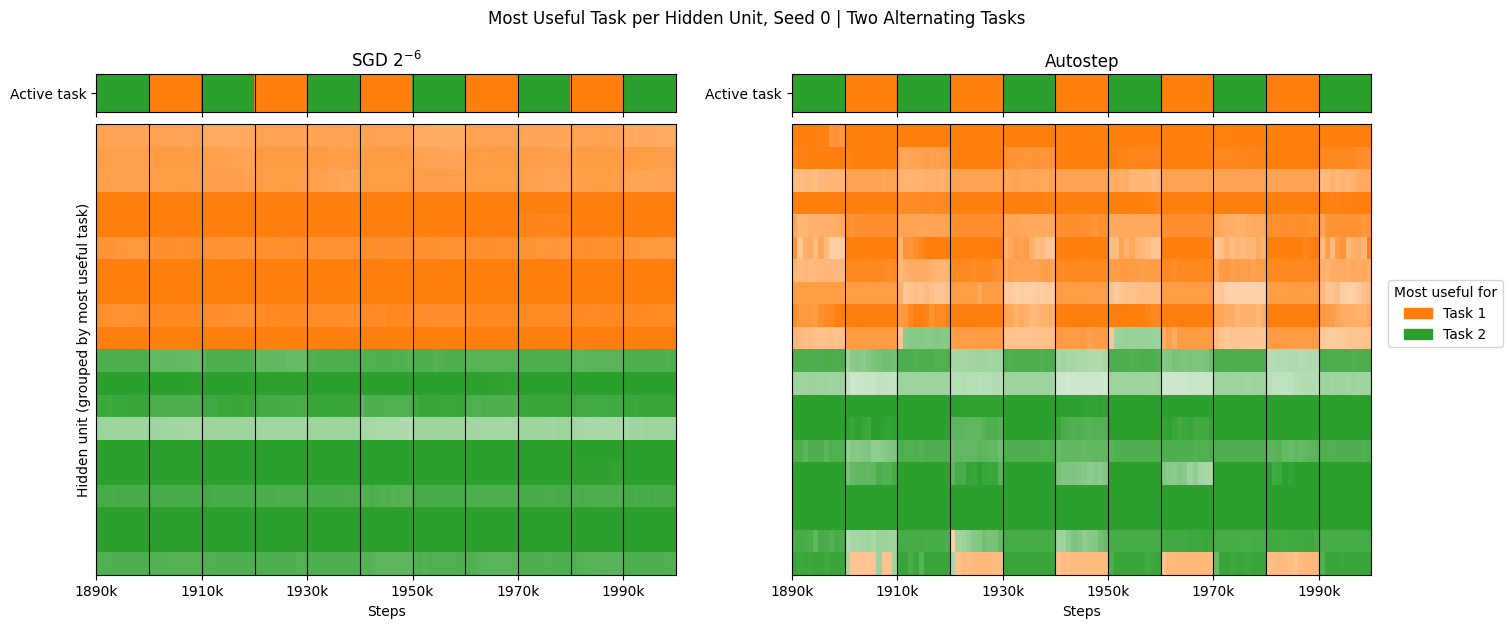

In [9]:
two_tasks = {rf'SGD $2^{{-6}}$': run('SGD', tasks=2), 'Autostep': run('Autostep', tasks=2)}
plot_units([(label, weights, 0) for label, (_, weights) in two_tasks.items()], 2, 'Two Alternating Tasks')